# Operational risk PoC: market-abuse fines
**Probability and impact for one bank, from free external data, with a Bayesian update.**

| Cell | Event | Party fined |
|---|---|---|
| A1 | Inside information (insider dealing, unlawful disclosure, insider lists, STOR, information barriers) | Bank |
| A2 | Inside information | Employee of the bank |
| B1 | Market manipulation (spoofing, benchmark rigging, other) | Bank |
| B2 | Market manipulation | Employee of the bank |
| M1 / M2 | All market abuse (A + B + type unknown, e.g. ESMA register) | Bank / Employee |

**How it works.** External fines on peer banks give a rate per bank-year, scaled to our bank's size. That rate is the *prior*. Our own history updates it (Gamma–Poisson). Fine amounts are scaled to our size and simulated to give the annual loss distribution.

The bank is never named: the only bank input is `inputs/bank_profile.csv` (year, total assets, optional internal event counts).

> **Data mode.** `DATA_MODE = "DEMO"` runs on synthetic data so every step can be shown. Switch to `"REAL"` once `inputs/events.csv` and `inputs/peer_panel.csv` are filled (see README).

In [1]:
# ---- Settings -------------------------------------------------------------
import os
DATA_MODE   = os.environ.get("OPRISK_DATA_MODE", "DEMO")   # "DEMO" or "REAL" (cloud run sets REAL)
BANK_REGION = "EU"        # EU, UK, US or OTHER - home region of our bank
TARGET_YEAR = 2026        # year we want the probability for
TARGET_SIZE = None        # EUR bn; None = last size in bank_profile grown by GROWTH
GROWTH      = 0.03
PRIOR_STRENGTH = None     # None = learnt from peer heterogeneity (1/alpha); or a number, e.g. 2
N_SIM = 200_000           # Monte Carlo years
LOSS_LEVELS_EUR = [1e5, 1e6, 1e7, 1e8]   # report P(annual loss > level)

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
import oprisk_engine as ore
pd.set_option("display.float_format", lambda v: f"{v:,.4f}" if abs(v) < 10 else f"{v:,.0f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
INP = Path("inputs")

## 1. Our bank (anonymous)

In [2]:
bank = pd.read_csv(INP / "bank_profile.csv").sort_values("year")
if TARGET_SIZE is None:
    last = bank.iloc[-1]
    TARGET_SIZE = float(last.total_assets_eur_bn * (1 + GROWTH) ** (TARGET_YEAR - last.year))
print(f"Target year {TARGET_YEAR}: assumed size EUR {TARGET_SIZE:,.1f} bn, region {BANK_REGION}")
bank.tail(8)

Target year 2026: assumed size EUR 86.3 bn, region EU


,year,total_assets_eur_bn,internal_data_available,n_A1,n_A2,n_B1,n_B2
18,2018,68,1,0,0,0,0
19,2019,70,1,0,1,0,0
20,2020,72,1,0,0,0,0
21,2021,74,1,0,0,0,0
22,2022,77,1,0,0,0,0
23,2023,79,1,0,0,0,0
24,2024,81,1,0,0,0,0
25,2025,84,1,0,0,0,0


## 2. External data: fines on peer banks and the full peer universe

In [3]:
if DATA_MODE == "DEMO":
    from demo_data import make_demo
    panel, notices = make_demo()
    print("DEMO MODE - synthetic data, not real fines")
else:
    panel = pd.read_csv(INP / "peer_panel.csv")        # built by build_universe.py
    notices = pd.read_csv(INP / "events.csv")          # built by build_universe.py
    # Only bank-years that were actually searched for fines count as exposure:
    # an unsearched year is not a zero-event year.
    coverage = pd.read_csv(INP / "coverage.csv")
    n0 = len(panel)
    panel = ore.apply_coverage(panel, coverage)
    print(f"Coverage filter: {n0} -> {len(panel)} bank-years kept")
    display(coverage)
regions = ["EU"] + sorted(r for r in set(panel.region) if r != "EU")
events = ore.cluster_events(notices)
events = events.merge(panel[["peer_id", "year"]], on=["peer_id", "year"], how="inner")  # needs exposure
n_ev = events.groupby("peer_id").size().reindex(panel.peer_id.unique()).fillna(0)
print(f"{len(notices)} notices -> {len(events)} events on universe banks in covered years")
print(f"Universe: {panel.peer_id.nunique()} banks, {len(panel)} bank-years, {panel.year.min()}-{panel.year.max()}")
print(f"Non-events: {(n_ev == 0).sum()} of {len(n_ev)} banks had no event at all - they stay in the denominator")
display(panel.groupby("region").agg(banks=("peer_id", "nunique"), bank_years=("year", "size"),
                                    median_size_eur_bn=("total_assets_eur_bn", "median")))
events.groupby("cell").agg(events=("cell", "size"), with_amount=("amount_eur", "count"),
                           median_eur=("amount_eur", "median"), max_eur=("amount_eur", "max"))

Coverage filter: 349 -> 349 bank-years kept


,region,first_year,last_year,sources_searched
0,EU,2013,2025,ESMA register (2010+) and FCA (2013+); complet...
1,UK,2013,2025,FCA fines tables 2013+
2,US,2013,2025,FCA and ESMA (fines on EU/UK activity only)
3,OTHER,2013,2025,FCA and ESMA (fines on EU/UK activity only)


13 notices -> 13 events on universe banks in covered years
Universe: 27 banks, 349 bank-years, 2013-2025
Non-events: 19 of 27 banks had no event at all - they stay in the denominator


,banks,bank_years,median_size_eur_bn
region,,,
EU,4,52,"1,179"
OTHER,11,141,873
UK,4,52,"1,202"
US,8,104,"1,401"


,events,with_amount,median_eur,max_eur
cell,,,,
A1,1,1,"14,687,946","14,687,946"
B1,9,9,"259,934,220","332,785,440"
B2,3,3,"210,600","292,500"


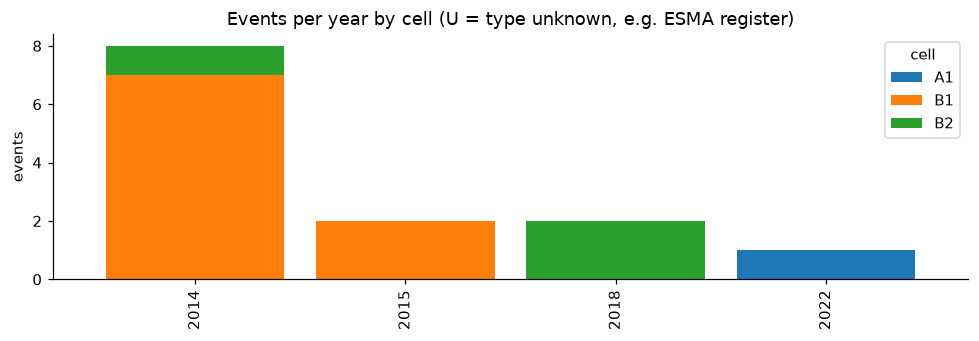

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.2))
tab = events.pivot_table(index="year", columns="cell", values="peer_id", aggfunc="size").fillna(0)
tab.plot(kind="bar", stacked=True, ax=ax, width=0.85)
ax.set_title("Events per year by cell (U = type unknown, e.g. ESMA register)"); ax.set_xlabel(""); ax.set_ylabel("events")
plt.tight_layout(); plt.show()

## 3. Reporting completeness (diagnostic)
Every reported event is counted for the probability, including events whose amount is unknown. Public data still misses small fines: below the peak of the amount distribution reporting looks incomplete. That level is shown here so the probabilities can be read as *probability of a publicly reported fine*.

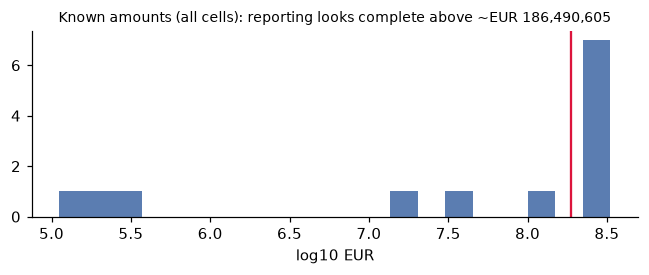

In [5]:
known = events.amount_eur.dropna()
u_report = ore.reporting_threshold(known.values) if len(known) else float("nan")
fig, ax = plt.subplots(figsize=(6, 2.6))
if len(known):
    ax.hist(np.log10(known[known > 0]), bins=20, color="#5b7db1")
    ax.axvline(np.log10(u_report), color="crimson", lw=1.5)
ax.set_title(f"Known amounts (all cells): reporting looks complete above ~EUR {u_report:,.0f}", fontsize=9)
ax.set_xlabel("log10 EUR"); plt.tight_layout(); plt.show()

## 4. Frequency model per cell (negative binomial)
`log λ = b0 + b1·(log size − centre) + period + region`, fitted on **all** bank-years of the universe, including banks that never had an event. `rate_multiplier` = effect on the yearly rate. `log_size_c` is an elasticity: 0.6 means a bank twice as big has 2^0.6 = 1.5× the rate. A weak N(0,2) prior keeps rare-event estimates finite. **M1/M2** pool all market-abuse events (A + B + type unknown).

In [6]:
fits, counts = {}, {}
for c in ore.CELLS:
    counts[c] = ore.build_counts(panel, events, c)
    fits[c] = ore.fit_nb(counts[c], regions)
    print(f"\n{c} - {ore.CELL_LABELS[c]}: {fits[c].n_events} events in {fits[c].n_obs} bank-years "
          f"(raw rate {fits[c].n_events / fits[c].n_obs:.4f}/bank-year); dispersion alpha = {fits[c].alpha:.2f}")
    display(fits[c].table())


A1 - Inside information - bank fined: 1 events in 349 bank-years (raw rate 0.0029/bank-year); dispersion alpha = 0.94


,coef,std_err,rate_multiplier
const,-5.9841,1.1689,0.0025
log_size_c,1.0251,1.2698,2.7873
period_MAR,-0.0164,1.3279,0.9837
region_OTHER,-0.7187,1.5975,0.4874
region_UK,-0.4660,1.6914,0.6275
region_US,0.8172,1.3339,2.2642



A2 - Inside information - employee fined: 0 events in 349 bank-years (raw rate 0.0000/bank-year); dispersion alpha = 1.00


,coef,std_err,rate_multiplier
const,-6.9719,1.3210,0.0009
log_size_c,0.0042,1.7577,1.0042
period_MAR,-0.5026,1.7049,0.6050
region_OTHER,-0.2788,1.8008,0.7567
region_UK,-0.1204,1.8973,0.8865
region_US,-0.2182,1.8329,0.8039



B1 - Market manipulation - bank fined: 9 events in 349 bank-years (raw rate 0.0258/bank-year); dispersion alpha = 0.17


...

,coef,std_err,rate_multiplier
const,-4.3792,0.9654,0.0125
log_size_c,-0.0681,1.0372,0.9341
period_MAR,-0.2735,1.0043,0.7607
region_OTHER,-1.4145,1.3859,0.2430
region_UK,1.1771,1.0510,3.2448
region_US,-1.2366,1.4198,0.2904



M1 - All market abuse - bank fined (A1+B1+type unknown): 10 events in 349 bank-years (raw rate 0.0287/bank-year); dispersion alpha = 0.17


,coef,std_err,rate_multiplier
const,-2.8372,0.7091,0.0586
log_size_c,1.2067,0.7259,3.3426
period_MAR,-2.9157,0.7878,0.0542
region_OTHER,-0.6092,1.0212,0.5438
region_UK,1.2958,0.8165,3.6540
region_US,0.4259,0.8611,1.5309



M2 - All market abuse - employee fined (A2+B2+type unknown): 3 events in 349 bank-years (raw rate 0.0086/bank-year); dispersion alpha = 0.73


,coef,std_err,rate_multiplier
const,-4.3792,0.9654,0.0125
log_size_c,-0.0681,1.0372,0.9341
period_MAR,-0.2735,1.0043,0.7607
region_OTHER,-1.4145,1.3859,0.2430
region_UK,1.1771,1.0510,3.2448
region_US,-1.2366,1.4198,0.2904


## 5. External (prior) probability for our bank

In [7]:
period_t = ore.period_of(TARGET_YEAR)
rows = []
for c in ore.CELLS:
    f = fits[c]
    mu = f.mu(np.log(TARGET_SIZE), period_t, BANK_REGION, regions)
    rows.append({"cell": c, "event": ore.CELL_LABELS[c], "events_in_data": f.n_events,
                 "lambda_per_year": mu, "P(>=1 fine in year)": ore.p_at_least_one_nb(mu, f.r),
                 "return_period_years": 1 / mu})
prior_tbl = pd.DataFrame(rows).set_index("cell")
prior_tbl

,event,events_in_data,lambda_per_year,P(>=1 fine in year),return_period_years
cell,,,,,
A1,Inside information - bank fined,1,0.0002,0.0002,"5,174"
A2,Inside information - employee fined,0,0.0006,0.0006,"1,781"
B1,Market manipulation - bank fined,9,0.0001,0.0001,"6,784"
B2,Market manipulation - employee fined,3,0.0113,0.0112,89
M1,All market abuse - bank fined (A1+B1+type unkn...,10,0.0002,0.0002,"6,347"
M2,All market abuse - employee fined (A2+B2+type ...,3,0.0113,0.0112,89


## 6. Bayesian update with our own history
Our yearly rate is `λ_t = θ · μ_t`: `μ_t` is the external rate for our size and regime in year *t*, `θ` is how our bank differs from a typical peer. Prior `θ ~ Gamma(r, r)` (mean 1); `r = 1/α` comes from how much peers differ from each other, or is set in `PRIOR_STRENGTH`.

After `n` internal events where the external model expected `E = Σ μ_t`: `θ ~ Gamma(r + n, r + E)`. Weight of our own data: `Z = E / (r + E)`.

In [8]:
hist = bank[bank.internal_data_available == 1].copy()
for c in ["A1", "A2", "B1", "B2"]:
    if f"n_{c}" not in hist:
        hist[f"n_{c}"] = 0
hist["n_M1"] = hist.get("n_M1", hist.n_A1 + hist.n_B1)
hist["n_M2"] = hist.get("n_M2", hist.n_A2 + hist.n_B2)

def mu_history(f):
    return np.array([f.mu(np.log(s), ore.period_of(int(y)), BANK_REGION, regions)
                     for y, s in zip(hist.year, hist.total_assets_eur_bn)])

bayes = {}
for c in ore.CELLS:
    r = PRIOR_STRENGTH or float(np.clip(fits[c].r, 0.5, 50))
    bayes[c] = ore.bayes_update(mu_history(fits[c]), int(hist[f"n_{c}"].sum()),
                                prior_tbl.loc[c, "lambda_per_year"], r)
post_tbl = pd.DataFrame(bayes).T[["prior_lambda", "prior_P1", "expected_internal_events",
                                  "observed_internal_events", "credibility_internal",
                                  "posterior_lambda", "posterior_P1"]]
print(f"Internal history: {len(hist)} years ({hist.year.min()}-{hist.year.max()})")
post_tbl

Internal history: 16 years (2010-2025)


,prior_lambda,prior_P1,expected_internal_events,observed_internal_events,credibility_internal,posterior_lambda,posterior_P1
A1,0.0002,0.0002,0.0024,0.0000,0.0023,0.0002,0.0002
A2,0.0006,0.0006,0.0112,1.0000,0.0111,0.0011,0.0011
B1,0.0001,0.0001,0.0210,0.0000,0.0036,0.0001,0.0001
B2,0.0113,0.0112,0.2058,0.0000,0.1307,0.0098,0.0097
M1,0.0002,0.0002,0.0121,0.0000,0.0021,0.0002,0.0002
M2,0.0113,0.0112,0.2058,1.0000,0.1307,0.0170,0.0168


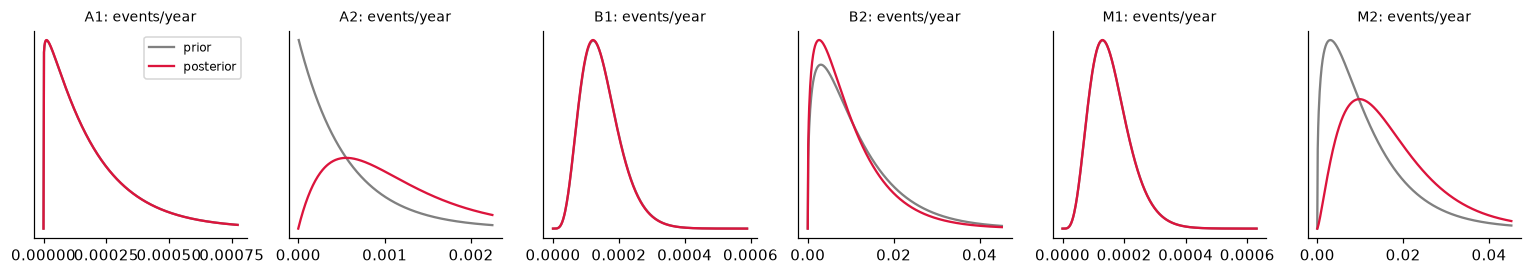

In [9]:
from scipy import stats
fig, axes = plt.subplots(1, len(ore.CELLS), figsize=(14, 2.6))
for ax, c in zip(axes, ore.CELLS):
    b = bayes[c]; mu = b["prior_lambda"]
    x = np.linspace(0, mu * 4, 400)
    ax.plot(x, stats.gamma.pdf(x / mu, b["r_prior"], scale=1 / b["r_prior"]) / mu, label="prior", color="grey")
    ax.plot(x, stats.gamma.pdf(x / mu, b["a_post"], scale=1 / b["b_post"]) / mu, label="posterior", color="crimson")
    ax.set_title(f"{c}: events/year", fontsize=9); ax.set_yticks([])
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

In [10]:
# Sensitivity of the posterior probability to the prior strength r
sens = {f"r={r}": {c: ore.bayes_update(mu_history(fits[c]), int(hist[f"n_{c}"].sum()),
                                       prior_tbl.loc[c, "lambda_per_year"], r)["posterior_P1"]
                   for c in ore.CELLS} for r in [0.5, 1, 2, 5, 10, 50]}
pd.DataFrame(sens).T.rename_axis("prior strength")

,A1,A2,B1,B2,M1,M2
prior strength,,,,,,
r=0.5,0.0002,0.0016,0.0001,0.0079,0.0002,0.0235
r=1,0.0002,0.0011,0.0001,0.0093,0.0002,0.0185
r=2,0.0002,0.0008,0.0001,0.0102,0.0002,0.0152
r=5,0.0002,0.0007,0.0001,0.0108,0.0002,0.0129
r=10,0.0002,0.0006,0.0001,0.0110,0.0002,0.0121
r=50,0.0002,0.0006,0.0001,0.0112,0.0002,0.0114


## 7. Severity, scaled to our size
Only events with a known amount are used here. Each fine is converted to its equivalent for our bank with the size elasticity of fine amounts (Dahen & Dionne-style scaling). A lognormal is fitted per cell; cells with fewer than 8 amounts borrow the amounts of the other cells of the same party (bank / employee). A GPD tail is added when there are ≥ 15 tail points.

In [11]:
elast_est, elast_se = ore.size_elasticity(events, panel)
n_amounts = int(events.amount_eur.notna().sum())
elast, elast_note = ore.size_elasticity_used(elast_est, elast_se, n_amounts)
print(f"Size elasticity of fine amounts used: {elast:.2f} - {elast_note}")
scaled = ore.scale_amounts(events, panel, TARGET_SIZE, elast)
sev, sev_src = {}, {}
for c in ore.CELLS:
    x, src = ore.severity_sample(scaled, c)
    if len(x) >= 3:
        # truncate at the smallest amount only when there are enough amounts to see it
        sev[c], sev_src[c] = ore.Severity(x, float(np.min(x)) if len(x) >= 20 else 1.0), src
desc = pd.DataFrame({c: {**s.describe(), "amounts_from": sev_src[c]} for c, s in sev.items()}).T
desc

Size elasticity of fine amounts used: 0.25 - literature value (estimate -0.25 from 13 amounts not reliable)


,n_used,threshold_eur,lognormal_median_eur,lognormal_sigma,amounts_from
A1,10,1.0000,"73,789,569",1.0519,"pooled (bank cells, 10 amounts)"
A2,3,1.0000,"99,013",0.4639,"pooled (employee cells, 3 amounts)"
B1,9,1.0000,"96,708,340",0.7055,own
B2,3,1.0000,"99,013",0.4639,"pooled (employee cells, 3 amounts)"
M1,10,1.0000,"73,789,569",1.0519,own
M2,3,1.0000,"99,013",0.4639,"pooled (employee cells, 3 amounts)"


## 8. Impact: Monte Carlo annual loss

In [12]:
loss = {c: ore.simulate_annual_loss(bayes[c]["a_post"], bayes[c]["b_post"],
                                    bayes[c]["prior_lambda"], sev[c], N_SIM, seed=i)
        for i, c in enumerate(ore.CELLS) if c in sev}
if "M1" in loss and "M2" in loss:
    loss["ALL"] = loss["M1"] + loss["M2"]   # M cells already contain A, B and unknown type
imp = pd.DataFrame({k: ore.loss_summary(v) for k, v in loss.items()}).T
for L in LOSS_LEVELS_EUR:
    imp[f"P(loss > {L:,.0f})"] = [np.mean(loss[k] > L) for k in imp.index]
imp

,P(any fine),expected_loss_eur,VaR_95.0%_eur,VaR_99.0%_eur,VaR_99.9%_eur,"P(loss > 100,000)","P(loss > 1,000,000)","P(loss > 10,000,000)","P(loss > 100,000,000)"
A1,0.0002,"23,761",0.0000,0.0000,0.0000,0.0002,0.0002,0.0002,0.0001
A2,0.0010,112,0.0000,0.0000,"41,094",0.0005,0.0000,0.0000,0.0000
B1,0.0002,"19,021",0.0000,0.0000,0.0000,0.0002,0.0002,0.0002,0.0001
B2,0.0098,"1,100",0.0000,0.0000,"182,854",0.0050,0.0000,0.0000,0.0000
M1,0.0001,"12,376",0.0000,0.0000,0.0000,0.0001,0.0001,0.0001,0.0000
M2,0.0169,"1,882",0.0000,"89,021","206,465",0.0085,0.0000,0.0000,0.0000
ALL,0.0171,"14,259",0.0000,"89,762","214,638",0.0086,0.0001,0.0001,0.0000


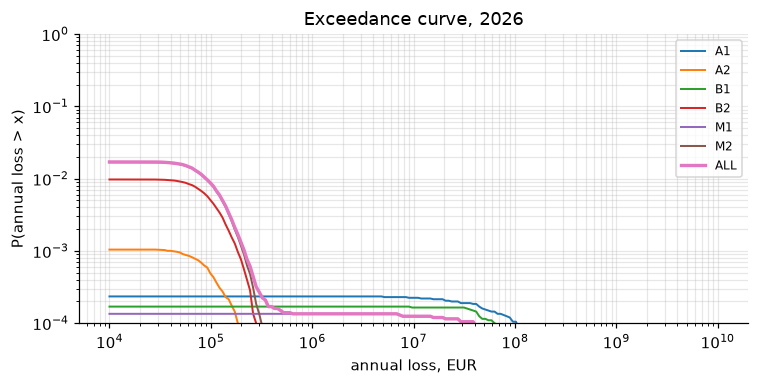

In [13]:
fig, ax = plt.subplots(figsize=(7, 3.6))
grid = np.logspace(4, 10, 200)
for k, v in loss.items():
    ax.plot(grid, [np.mean(v > g) for g in grid], label=k, lw=2.2 if k == "ALL" else 1.3)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(1e-4, 1)
ax.set_xlabel("annual loss, EUR"); ax.set_ylabel("P(annual loss > x)")
ax.set_title(f"Exceedance curve, {TARGET_YEAR}"); ax.legend(fontsize=8); ax.grid(alpha=.3, which="both")
plt.tight_layout(); plt.show()

## 9. Summary

In [14]:
keys = ore.CELLS + (["ALL"] if "ALL" in loss else [])
summary = pd.DataFrame({
    "event": [ore.CELL_LABELS.get(c, "All market abuse (M1 + M2)") for c in keys],
    "P(>=1 fine) external": [prior_tbl.loc[c, "P(>=1 fine in year)"] if c in prior_tbl.index else np.nan for c in keys],
    "P(>=1 fine) after Bayes": [bayes[c]["posterior_P1"] if c in bayes else imp.loc[c, "P(any fine)"] for c in keys],
    "weight of internal data": [bayes[c]["credibility_internal"] if c in bayes else np.nan for c in keys],
    "expected loss EUR": [imp.loc[c, "expected_loss_eur"] if c in imp.index else np.nan for c in keys],
    "VaR 99.9% EUR": [imp.loc[c, "VaR_99.9%_eur"] if c in imp.index else np.nan for c in keys],
}, index=keys)
if DATA_MODE == "DEMO":
    print("DEMO MODE - figures come from synthetic data and are illustrative only")
summary

,event,P(>=1 fine) external,P(>=1 fine) after Bayes,weight of internal data,expected loss EUR,VaR 99.9% EUR
A1,Inside information - bank fined,0.0002,0.0002,0.0023,"23,761",0.0000
A2,Inside information - employee fined,0.0006,0.0011,0.0111,112,"41,094"
B1,Market manipulation - bank fined,0.0001,0.0001,0.0036,"19,021",0.0000
B2,Market manipulation - employee fined,0.0112,0.0097,0.1307,"1,100","182,854"
M1,All market abuse - bank fined (A1+B1+type unkn...,0.0002,0.0002,0.0021,"12,376",0.0000
M2,All market abuse - employee fined (A2+B2+type ...,0.0112,0.0168,0.1307,"1,882","206,465"
ALL,All market abuse (M1 + M2),NaN,0.0171,NaN,"14,259","214,638"


In [15]:
# Save results for the phone page / later comparison
import json, datetime
out = Path("results"); out.mkdir(exist_ok=True)
summary.to_csv(out / "summary.csv")
prior_tbl.to_csv(out / "prior_probabilities.csv")
post_tbl.to_csv(out / "posterior_probabilities.csv")
pd.DataFrame(sens).T.to_csv(out / "prior_sensitivity.csv")
imp.to_csv(out / "impact.csv")
grid = np.logspace(4, 10, 61)
pd.DataFrame({k: [float(np.mean(v > g)) for g in grid] for k, v in loss.items()},
             index=pd.Index(grid, name="loss_eur")).to_csv(out / "exceedance.csv")
pd.concat({c: fits[c].table() for c in ore.CELLS}).to_csv(out / "frequency_models.csv")
meta = {"run_utc": datetime.datetime.utcnow().isoformat(timespec="seconds"), "data_mode": DATA_MODE,
        "target_year": TARGET_YEAR, "target_size_eur_bn": TARGET_SIZE, "bank_region": BANK_REGION,
        "n_banks": int(panel.peer_id.nunique()), "n_bank_years": int(len(panel)),
        "n_banks_no_event": int((n_ev == 0).sum()), "n_events": int(len(events)),
        "events_by_cell": events.cell.value_counts().to_dict(),
        "banks_by_region": panel.groupby("region").peer_id.nunique().to_dict(),
        "years": [int(panel.year.min()), int(panel.year.max())],
        "size_elasticity": elast, "elasticity_note": elast_note, "internal_years": int(len(hist))}
(out / "run_meta.json").write_text(json.dumps(meta, indent=1, default=str))
# Everything a browser needs to recompute the probabilities for ANY bank size
if "peer_name" not in panel:
    panel["peer_name"] = panel["peer_id"]
model = {"meta": meta, "periods": [[p, lo, hi] for p, lo, hi in ore.PERIODS], "regions": regions,
         "cells": {}, "size_fit_eur_bn": TARGET_SIZE, "elasticity": elast,
         "universe": panel.groupby(["peer_id", "peer_name", "region"]).total_assets_eur_bn.last()
                          .reset_index().assign(events=lambda d: d.peer_id.map(n_ev)).to_dict("records"),
         "events": events.assign(date=events.date.astype(str)).merge(
                          panel[["peer_id", "peer_name"]].drop_duplicates(), on="peer_id", how="left")
                          [["date", "peer_name", "cell", "amount_eur", "regulators"]].to_dict("records")}
for c in ore.CELLS:
    f = fits[c]
    cell = {"label": ore.CELL_LABELS[c], "names": f.names, "beta": [float(x) for x in f.beta],
            "alpha": f.alpha, "size_center": f.size_center, "n_events": f.n_events, "n_obs": f.n_obs}
    if c in sev:
        s_ = sev[c]
        cell["severity"] = {"mu_log": s_.mu_log, "sigma_log": s_.sigma_log, "u": s_.u,
                            "tail_u": float(s_.tail_u), "p_tail": s_.p_tail,
                            "gpd": list(s_.gpd) if s_.gpd else None, "source": sev_src[c], "n": s_.n}
    model["cells"][c] = cell
(out / "model.json").write_text(json.dumps(model, default=lambda o: None if o != o else float(o)))
print("Results saved to", out.resolve())

Results saved to /home/runner/work/Oprisk-poc/Oprisk-poc/results


/tmp/ipykernel_2647/3723109315.py:13: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  meta = {"run_utc": datetime.datetime.utcnow().isoformat(timespec="seconds"), "data_mode": DATA_MODE,


### Caveats to state in the pitch
- **Public data is a censored view.** Only disclosed fines are seen; probabilities are of a *publicly reported* fine.
- **Who is in the universe.** EU/EEA banks in the EBA transparency exercise (the larger banks) plus large US, Swiss, UK, Japanese and Canadian banks with EU/UK activity. A much smaller bank is outside the range the model was fitted on.
- **Only EU/UK regulators are searched** (FCA, ESMA register). For non-EU banks this measures fines on their EU/UK activity, not worldwide.
- **ESMA cases have no type or amount.** They count only in M1/M2 and in the frequency, never in severity.
- **Employee cells (A2, B2)** need each fined individual linked to their employer bank by hand.
- **Regime effects.** Enforcement intensity changed in 2005 (MAD) and 2016 (MAR); the period terms absorb this and the target year uses the MAR level.
- **Independence across cells** is assumed in the combined figure; a single scandal can hit A1 and A2 together, so the combined tail is likely understated.
- **FX and inflation.** Amounts use the FX table in `inputs/fx_rates.csv`; no inflation adjustment yet.